<a href="https://colab.research.google.com/github/majidiitk-git/README/blob/main/Functional_Enrichment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Functional enrichment on all 15 genes obtained from DEA (blood genes excluded)

Number of genes used for enrichment: 15
Genes:
['S100A9', 'VEGFA', 'NPTX2', 'S100A8', 'CXCL9', 'GADD45B', 'WIF1', 'RPH3A', 'APOLD1', 'ADM', 'PSPH', 'AQP1', 'DDX17', 'C10orf10', 'IFITM1']
GO-BP ENRICHMENT

Total terms tested: 396
Significant terms (adjusted p < 0.05): 229

Top enriched terms:


,Term,Gene_Ratio_Display,Adjusted P-value,Gene_List
0,peptidyl-cysteine S-nitrosylation (GO:0018119),2/15,0.001366,S100A9; S100A8
1,leukocyte aggregation (GO:0070486),2/15,0.001366,S100A9; S100A8
2,neutrophil chemotaxis (GO:0030593),3/15,0.001366,CXCL9; S100A9; S100A8
3,peptidyl-cysteine modification (GO:0018198),2/15,0.001366,S100A9; S100A8
4,granulocyte chemotaxis (GO:0071621),3/15,0.001366,CXCL9; S100A9; S100A8
5,inflammatory response (GO:0006954),4/15,0.001366,CXCL9; ADM; S100A9; S100A8
6,neutrophil migration (GO:1990266),3/15,0.001366,CXCL9; S100A9; S100A8
7,positive regulation of p38MAPK cascade (GO:190...,2/15,0.006315,GADD45B; VEGFA
8,defense response to fungus (GO:0050832),2/15,0.006315,S100A9; S100A8
9,response to lipopolysaccharide (GO:0032496),3/15,0.008281,CXCL9; S100A9; S100A8


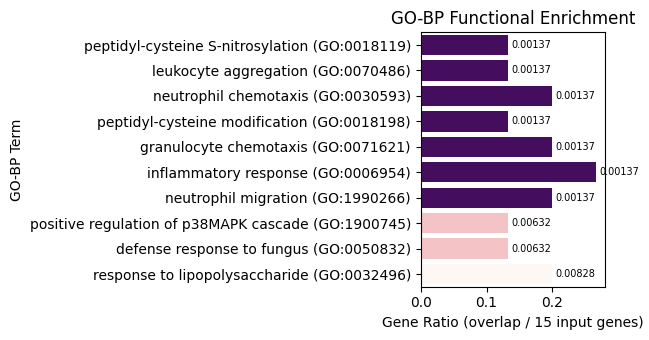

GO-MF ENRICHMENT

Total terms tested: 49
Significant terms (adjusted p < 0.05): 30

Top enriched terms:


,Term,Gene_Ratio_Display,Adjusted P-value,Gene_List
0,arachidonic acid binding (GO:0050544),2/15,0.000180,S100A9; S100A8
1,icosatetraenoic acid binding (GO:0050543),2/15,0.000180,S100A9; S100A8
2,icosanoid binding (GO:0050542),2/15,0.000180,S100A9; S100A8
3,RAGE receptor binding (GO:0050786),2/15,0.000231,S100A9; S100A8
4,Toll-like receptor binding (GO:0035325),2/15,0.000282,S100A9; S100A8
5,metal ion binding (GO:0046872),4/15,0.003921,RPH3A; S100A9; S100A8; PSPH
6,zinc ion binding (GO:0008270),3/15,0.012460,RPH3A; S100A9; S100A8
7,calcium ion binding (GO:0005509),3/15,0.012460,RPH3A; S100A9; S100A8
8,polyol transmembrane transporter activity (GO:...,1/15,0.018169,AQP1
9,CXCR3 chemokine receptor binding (GO:0048248),1/15,0.018169,CXCL9


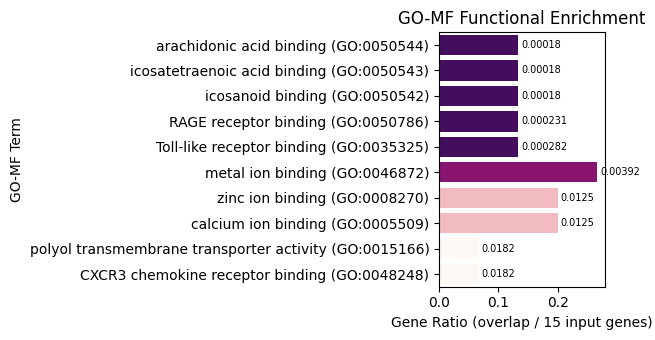

GO-CC ENRICHMENT

Total terms tested: 26
Significant terms (adjusted p < 0.05): 2

Top enriched terms:


,Term,Gene_Ratio_Display,Adjusted P-value,Gene_List
0,secretory granule lumen (GO:0034774),3/15,0.040142,S100A9; S100A8; VEGFA
1,cytoplasmic vesicle lumen (GO:0060205),2/15,0.042603,S100A9; S100A8


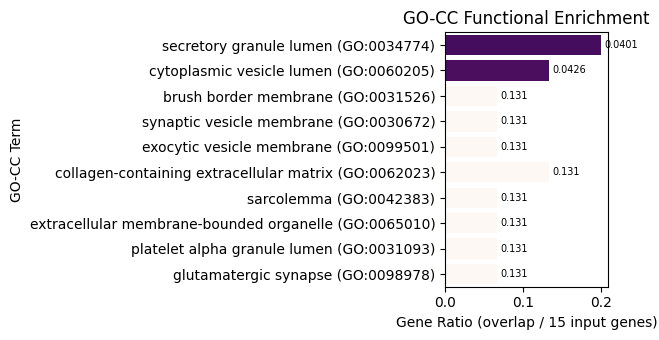

In [5]:
# Install
!pip install -q gseapy pandas matplotlib seaborn openpyxl

import gseapy as gp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

gene_list = [
    "S100A9", "VEGFA", "NPTX2", "S100A8", "CXCL9",
    "GADD45B", "WIF1", "RPH3A", "APOLD1", "ADM",
    "PSPH", "AQP1", "DDX17", "C10orf10", "IFITM1"
]

# Remove duplicates and empty values
gene_list = list(dict.fromkeys(gene_list))

INPUT_GENE_COUNT = len(gene_list)

print("Number of genes used for enrichment:", INPUT_GENE_COUNT)
print("Genes:")
print(gene_list)

go_sets = {
    "BP": "GO_Biological_Process_2021",
    "MF": "GO_Molecular_Function_2021",
    "CC": "GO_Cellular_Component_2021"
}

# ENRICHMENT ANALYSIS

def run_enrichment(gene_list, go_type, gene_set):


    print(f"GO-{go_type} ENRICHMENT")

    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets=gene_set,
        organism="human",
        cutoff=1.0,
        outdir=None
    )

    results = enr.results.copy()

    if results.empty:
        print(f"No results for GO-{go_type}")
        return None

    results["Overlap_Count"] = (
        results["Overlap"]
        .str.split("/")
        .str[0]
        .astype(int)
    )

    results["Gene_Set_Size"] = (
        results["Overlap"]
        .str.split("/")
        .str[1]
        .astype(int)
    )

    # Gene ratio
    # Number of input genes contributing to the term /
    # total number of input genes

    results["Gene_Ratio"] = (
        results["Overlap_Count"] / INPUT_GENE_COUNT
    )

    results["Gene_Ratio_Display"] = (
        results["Overlap_Count"].astype(str)
        + "/"
        + str(INPUT_GENE_COUNT)
    )


    results["Genes"] = results["Genes"].fillna("")

    results["Gene_List"] = results["Genes"].apply(
        lambda x: "; ".join(
            [g.strip() for g in x.split(";") if g.strip()]
        )
    )


    results["Background_Type"] = "Enrichr library background"
    results["Background_Size"] = np.nan

    # Select useful columns
    results = results[
        [
            "Gene_set",
            "Term",
            "Overlap_Count",
            "Gene_Ratio",
            "Gene_Ratio_Display",
            "Gene_Set_Size",
            "P-value",
            "Adjusted P-value",
            "Odds Ratio",
            "Combined Score",
            "Gene_List",
            "Background_Type",
            "Background_Size"
        ]
    ]

    # Sort by adjusted p-value
    results = results.sort_values(
        "Adjusted P-value"
    ).reset_index(drop=True)

    results.to_csv(
        f"GO_{go_type}_complete_enrichment_results.csv",
        index=False
    )

    significant = results[
        results["Adjusted P-value"] < 0.05
    ].copy()

    significant.to_csv(
        f"GO_{go_type}_significant_enrichment_results.csv",
        index=False
    )

    print(f"\nTotal terms tested: {len(results)}")
    print(f"Significant terms (adjusted p < 0.05): {len(significant)}")

    print("\nTop enriched terms:")
    display(
        significant[
            [
                "Term",
                "Gene_Ratio_Display",
                "Adjusted P-value",
                "Gene_List"
            ]
        ].head(10)
    )

    # PLOT
    top_results = results.head(10).copy()

    if not top_results.empty:

        plt.figure(figsize=(6.5, 3.5))

        sns.barplot(
            data=top_results,
            x="Gene_Ratio",
            y="Term",
            hue="Adjusted P-value",
            dodge=False,
            palette="RdPu_r"
        )

        plt.xlabel(
            f"Gene Ratio (overlap / {INPUT_GENE_COUNT} input genes)"
        )

        plt.ylabel(f"GO-{go_type} Term")

        plt.title(
            f"GO-{go_type} Functional Enrichment"
        )

        plt.legend().remove()

        # Add adjusted p-value against each corresponding bar

        for i, (_, row) in enumerate(top_results.iterrows()):

            plt.text(
                row["Gene_Ratio"] + 0.005,
                i,
                f"{row['Adjusted P-value']:.3g}",
                va="center",
                fontsize=7
            )

        plt.tight_layout()
        plt.show()

    return results

# RUN BP, MF AND CC

all_results = {}

for go_type, gene_set in go_sets.items():

    results = run_enrichment(
        gene_list,
        go_type,
        gene_set
    )

    all_results[go_type] = results

# COMBINE RESULTS INTO ONE SUPPLEMENTARY TABLE

combined_results = pd.concat(
    [
        df.assign(GO_Category=go_type)
        for go_type, df in all_results.items()
        if df is not None
    ],
    ignore_index=True
)

combined_results = combined_results[
    [
        "GO_Category",
        "Gene_set",
        "Term",
        "Overlap_Count",
        "Gene_Ratio",
        "Gene_Ratio_Display",
        "Gene_Set_Size",
        "P-value",
        "Adjusted P-value",
        "Odds Ratio",
        "Combined Score",
        "Gene_List",
        "Background_Type",
        "Background_Size"
    ]
]

# combined_results.to_csv(
#     "Supplementary_GO_Enrichment_Statistics.csv",
#     index=False
# )

# # Also save Excel version
# combined_results.to_excel(
#     "Supplementary_GO_Enrichment_Statistics.xlsx",
#     index=False
# )